# Laboratory Assignment 8: High-Performance Big Data Analytics Using R
**Name:** Vicky Pukale  **Roll No.:** 23102A0033  **Git repository:** https://github.com/vickypukale/23102A0033_R_PROGRAMMING/EXP_8

## 1. Problem Statement
Develop a high-performance, scalable analytics solution in R on the NYC Yellow Taxi dataset. Use `data.table` for manipulation, compare functional (`apply`/`lapply`/`purrr::map`), vectorized and `data.table` implementations, run a computationally heavy operation sequentially and in parallel (`foreach` + `doParallel`), benchmark all approaches, visualize results with `ggplot2`, and critically evaluate which approach suits large-scale analytics.

## 2. Dataset
NYC TLC **Yellow Taxi Trip Records**, January-June 2024 (parquet, https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page) plus the **Taxi Zone Lookup Table** for mapping Location IDs to Zone/Borough. Attributes: pickup/drop-off time, pickup/drop-off Location ID, passenger count, trip distance, payment type, fare, tip, tolls, total amount.

**Workflow:** Problem Statement -> Dataset -> Data Preparation -> Implementation -> Analysis -> Benchmarking -> Visualizations -> Observations -> Critical Analysis -> Conclusion

## Setup
Install/load packages and set the random seed.

In [1]:
pkgs <- c("data.table", "ggplot2", "foreach", "doParallel", "microbenchmark",
          "purrr", "arrow", "bench", "scales")
new <- setdiff(pkgs, rownames(installed.packages()))
if (length(new)) install.packages(new)
invisible(lapply(pkgs, library, character.only = TRUE))
set.seed(42)
dir.create("data", showWarnings = FALSE); dir.create("figs", showWarnings = FALSE)
cat("Logical cores available:", detectCores(), "\n")

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘iterators’, ‘assertthat’, ‘profmem’



Attaching package: ‘data.table’


The following object is masked from ‘package:base’:

    %notin%


Loading required package: iterators

Loading required package: parallel


Attaching package: ‘purrr’


The following objects are masked from ‘package:foreach’:

    accumulate, when


The following object is masked from ‘package:data.table’:

    transpose



Attaching package: ‘arrow’


The following object is masked from ‘package:utils’:

    timestamp



Attaching package: ‘scales’


The following object is masked from ‘package:purrr’:

    discard




Logical cores available: 2 


## 3. Data Preparation (Task 1)
Import, inspect, clean, type-convert, derive temporal features, and join the zone lookup using `data.table`.

In [2]:
MONTHS    <- sprintf("2024-%02d", 1:6)
BASE_URL  <- "https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_%s.parquet"
ZONE_URL  <- "https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv"
KEEP_COLS <- c("tpep_pickup_datetime", "tpep_dropoff_datetime", "passenger_count",
               "trip_distance", "PULocationID", "DOLocationID", "payment_type",
               "fare_amount", "tip_amount", "tolls_amount", "total_amount")

read_month <- function(m) {
  f <- file.path("data", sprintf("yellow_tripdata_%s.parquet", m))
  if (!file.exists(f)) download.file(sprintf(BASE_URL, m), f, mode = "wb", quiet = TRUE)
  as.data.table(arrow::read_parquet(f, col_select = KEEP_COLS))
}

t_load <- system.time(trips <- rbindlist(lapply(MONTHS, read_month)))
cat("Load time (s):", t_load[["elapsed"]], "\n")

Warning message:
“Using an external vector in selections was deprecated in tidyselect 1.1.0.
ℹ Please use `all_of()` or `any_of()` instead.
  # Was:
  data %>% select(KEEP_COLS)

  # Now:
  data %>% select(all_of(KEEP_COLS))

See <https://tidyselect.r-lib.org/reference/faq-external-vector.html>.”


Load time (s): 9.327 


In [3]:
## 1.2 Inspect structure, dimensions, types, summary
cat("Dimensions:", dim(trips), "\n")
str(trips)
print(summary(trips))
mem_raw <- object.size(trips)
cat("Memory (raw):", format(mem_raw, units = "MB"), "\n")

Dimensions: 20332093 11 
Classes ‘data.table’ and 'data.frame':	20332093 obs. of  11 variables:
 $ tpep_pickup_datetime : POSIXct, format: "2024-01-01 00:57:55" "2024-01-01 00:03:00" ...
 $ tpep_dropoff_datetime: POSIXct, format: "2024-01-01 01:17:43" "2024-01-01 00:09:36" ...
 $ passenger_count      : int  1 1 1 1 1 1 2 0 1 1 ...
 $ trip_distance        : num  1.72 1.8 4.7 1.4 0.8 ...
 $ PULocationID         : int  186 140 236 79 211 148 138 246 161 113 ...
 $ DOLocationID         : int  79 236 79 211 148 141 181 231 261 113 ...
 $ payment_type         : int  2 1 1 1 1 1 1 2 2 2 ...
 $ fare_amount          : num  17.7 10 23.3 10 7.9 29.6 45.7 25.4 31 3 ...
 $ tip_amount           : num  0 3.75 3 2 3.2 6.9 10 0 0 0 ...
 $ tolls_amount         : num  0 0 0 0 0 0 0 0 0 0 ...
 $ total_amount         : num  22.7 18.8 31.3 17 16.1 ...
 - attr(*, ".internal.selfref")=<pointer: 0x588dd8b463f0> 
 tpep_pickup_datetime          tpep_dropoff_datetime         passenger_count  
 Min.   :2002-12-31 

In [4]:
## 1.3 Missing / duplicate / invalid records
cat("\nMissing values per column:\n")
print(trips[, lapply(.SD, function(x) sum(is.na(x)))])

n_raw <- nrow(trips)
trips <- unique(trips)                       # exact duplicate rows
cat("Duplicates removed:", n_raw - nrow(trips), "\n")


Missing values per column:
   tpep_pickup_datetime tpep_dropoff_datetime passenger_count trip_distance
                  <int>                 <int>           <int>         <int>
1:                    0                     0         1975985             0
   PULocationID DOLocationID payment_type fare_amount tip_amount tolls_amount
          <int>        <int>        <int>       <int>      <int>        <int>
1:            0            0            0           0          0            0
   total_amount
          <int>
1:            0
Duplicates removed: 1 


In [5]:
## 1.5 Temporal features (data.table's fast built-in date helpers)
trips[, `:=`(
  duration_min = as.numeric(difftime(tpep_dropoff_datetime, tpep_pickup_datetime, units = "mins")),
  pickup_date  = as.IDate(tpep_pickup_datetime),
  pickup_hour  = hour(tpep_pickup_datetime),
  pickup_day   = mday(tpep_pickup_datetime),
  pickup_dow   = factor(wday(tpep_pickup_datetime), 1:7,
                        c("Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat")),
  pickup_month = month(tpep_pickup_datetime),
  pickup_year  = year(tpep_pickup_datetime)
)]

In [6]:
## Validity rules (inconsistent / impossible values)
trips[, invalid := is.na(passenger_count) | !passenger_count %in% 1:6 |
        pickup_year != 2024 | !pickup_month %in% 1:6 |
        trip_distance <= 0 | trip_distance > 100 |
        fare_amount <= 0 | fare_amount > 1000 |
        total_amount <= 0 | total_amount > 1500 |
        tip_amount < 0 | tolls_amount < 0 |
        duration_min < 1 | duration_min > 300 |
        !PULocationID %in% 1:265 | !DOLocationID %in% 1:265]
cat("Invalid rows:", sum(trips$invalid), sprintf("(%.2f%%)\n", 100 * mean(trips$invalid)))
trips <- trips[invalid == FALSE][, invalid := NULL]

Invalid rows: 2732145 (13.44%)


In [7]:
## 1.4 Convert data types
trips[, `:=`(
  passenger_count = as.integer(passenger_count),
  payment_type    = factor(payment_type, levels = 0:6,
                           labels = c("Flex fare", "Credit card", "Cash", "No charge",
                                      "Dispute", "Unknown", "Voided")),
  month_lab       = factor(month.abb[pickup_month], levels = month.abb[1:6]),
  is_weekend      = pickup_dow %in% c("Sat", "Sun"),
  daypart = fcase(pickup_hour %in% 6:9,   "Morning peak (6-9)",
                  pickup_hour %in% 10:15, "Midday (10-15)",
                  pickup_hour %in% 16:19, "Evening peak (16-19)",
                  pickup_hour %in% 20:23, "Night (20-23)",
                  default = "Late night (0-5)")
)]
trips[, daypart := factor(daypart, levels = c("Late night (0-5)", "Morning peak (6-9)",
        "Midday (10-15)", "Evening peak (16-19)", "Night (20-23)"))]

In [8]:
## 1.6 Drop unneeded columns to cut memory
trips[, c("tpep_pickup_datetime", "tpep_dropoff_datetime", "pickup_year") := NULL]
gc()
cat("Memory (clean):", format(object.size(trips), units = "MB"), "\n")

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,1488673,79.6,2730082,145.9,2021183,108
Vcells,213927633,1632.2,559788515,4270.9,552851958,4218


Memory (clean): 1611.3 Mb 


In [9]:
## 1.7-1.9 Zone lookup + joins (data.table update-joins by reference, no copies)
zones <- fread(ZONE_URL)
setnames(zones, c("LocationID", "Borough", "Zone", "service_zone"))
print(head(zones))
trips[zones, `:=`(PU_Borough = i.Borough, PU_Zone = i.Zone), on = .(PULocationID = LocationID)]
trips[zones, `:=`(DO_Borough = i.Borough, DO_Zone = i.Zone), on = .(DOLocationID = LocationID)]
cat("Rows after cleaning:", nrow(trips), "\n")
print(trips[, .N, by = PU_Borough][order(-N)])

   LocationID       Borough                    Zone service_zone
        <int>        <char>                  <char>       <char>
1:          1           EWR          Newark Airport          EWR
2:          2        Queens             Jamaica Bay    Boro Zone
3:          3         Bronx Allerton/Pelham Gardens    Boro Zone
4:          4     Manhattan           Alphabet City  Yellow Zone
5:          5 Staten Island           Arden Heights    Boro Zone
6:          6 Staten Island Arrochar/Fort Wadsworth    Boro Zone
Rows after cleaning: 17599947 
      PU_Borough        N
          <char>    <int>
1:     Manhattan 15730722
2:        Queens  1643635
3:      Brooklyn   133922
4:       Unknown    56308
5:         Bronx    32743
6:           N/A     2238
7: Staten Island      225
8:           EWR      154


## 4. Implementation and Analysis (Task 2)
Trips by hour/day/month, fares and revenue by period, top routes, distance-fare relationship, payment patterns, extra patterns.

In [10]:
summ <- function(grp) trips[, .(trips = .N, avg_fare = mean(fare_amount),
                                avg_total = mean(total_amount),
                                revenue = sum(total_amount)), keyby = grp]

by_hour  <- summ("pickup_hour")                     # Q1
by_dow   <- summ("pickup_dow")                      # Q2
by_month <- summ("month_lab")                       # Q3
by_dpart <- summ("daypart")                         # Q4
daily    <- summ("pickup_date")
by_hour_wk <- summ(c("pickup_hour", "is_weekend"))
print(by_hour); print(by_dow); print(by_month); print(by_dpart)

Key: <pickup_hour>
    pickup_hour   trips avg_fare avg_total  revenue
          <int>   <int>    <num>     <num>    <num>
 1:           0  464870 19.75058  29.07844 13517694
 2:           1  304950 17.50699  26.06931  7949836
 3:           2  200195 16.28955  24.49563  4903902
 4:           3  130230 17.34413  25.73724  3351761
 5:           4   81331 23.41558  33.17790  2698391
 6:           5   96177 27.75930  38.48527  3701398
 7:           6  228413 23.01934  31.74584  7251162
 8:           7  468772 19.23674  27.38724 12838370
 9:           8  655016 18.22747  26.21610 17171968
10:           9  754814 18.36370  26.48206 19989031
11:          10  826087 18.74415  26.99200 22297738
12:          11  895482 18.80250  26.97934 24159516
13:          12  972609 19.09229  27.37740 26627506
14:          13 1005987 19.88975  28.42689 28597081
15:          14 1080600 20.60350  29.36815 31735221
16:          15 1107927 20.54259  29.27888 32438864
17:          16 1122495 20.50910  31.19244 35

In [11]:
## Q5/Q6 routes (exclude unknown zones)
routes <- trips[!is.na(PU_Zone) & !is.na(DO_Zone) &
                  !PU_Zone %in% c("Unknown", "N/A") & !DO_Zone %in% c("Unknown", "N/A"),
                .(trips = .N, revenue = sum(total_amount), avg_fare = mean(fare_amount),
                  avg_dist = mean(trip_distance)), by = .(PU_Zone, DO_Zone)]
routes[, route := paste(PU_Zone, "->", DO_Zone)]
top_routes_freq <- routes[order(-trips)][1:15]
top_routes_rev  <- routes[order(-revenue)][1:15]
print(top_routes_freq[, .(route, trips, revenue)])
print(top_routes_rev[,  .(route, trips, revenue)])

top_pu <- trips[!PU_Zone %in% c("Unknown", "N/A"), .N, by = PU_Zone][order(-N)][1:15]
top_do <- trips[!DO_Zone %in% c("Unknown", "N/A"), .N, by = DO_Zone][order(-N)][1:15]

                                             route  trips   revenue
                                            <char>  <int>     <num>
 1: Upper East Side South -> Upper East Side North 132542 2084693.3
 2: Upper East Side North -> Upper East Side South 113701 1834516.5
 3: Upper East Side North -> Upper East Side North  87055 1141400.4
 4: Upper East Side South -> Upper East Side South  84818 1168057.3
 5:        Midtown Center -> Upper East Side South  63248 1093741.3
 6:        Upper East Side South -> Midtown Center  54645  934979.4
 7:        Midtown Center -> Upper East Side North  53100 1173102.4
 8:   Lincoln Square East -> Upper West Side South  50572  758406.9
 9:   Upper West Side South -> Lincoln Square East  50361  731663.4
10:          Upper East Side South -> Midtown East  48891  796835.4
11: Upper West Side South -> Upper West Side North  47293  654084.0
12:       Lenox Hill West -> Upper East Side North  43494  685866.2
13:       JFK Airport -> Times Sq/Theatre Distri

In [12]:
## Q7 distance vs fare
cat("Correlation (distance, fare):", cor(trips$trip_distance, trips$fare_amount), "\n")
fit <- lm(fare_amount ~ trip_distance, data = trips[sample(.N, min(.N, 1e6))])
print(summary(fit)$coefficients); cat("R^2:", summary(fit)$r.squared, "\n")
dist_bins <- trips[, .(trips = .N, avg_fare = mean(fare_amount),
                       fare_per_mile = sum(fare_amount) / sum(trip_distance)),
                   keyby = .(dist_bin = cut(trip_distance, c(0, 1, 2, 3, 5, 10, 20, 100)))]
print(dist_bins)

Correlation (distance, fare): 0.9500386 
              Estimate  Std. Error   t value Pr(>|t|)
(Intercept)   6.530836 0.006883324  948.7911        0
trip_distance 3.743886 0.001227756 3049.3728        0
R^2: 0.9029003 
Key: <dist_bin>
   dist_bin   trips avg_fare fare_per_mile
     <fctr>   <int>    <num>         <num>
1:    (0,1] 4231308  7.72686     10.940084
2:    (1,2] 5859623 11.89425      8.124159
3:    (2,3] 2721936 16.82998      6.883874
4:    (3,5] 1862484 22.80058      6.003324
5:   (5,10] 1455661 35.10869      4.786964
6:  (10,20] 1287579 61.76466      4.145693
7: (20,100]  181356 91.13917      3.778563


In [13]:
## Q8 payment by borough
pay_borough <- trips[!PU_Borough %in% c("Unknown", "N/A"), .N, by = .(PU_Borough, payment_type)]
pay_borough[, share := N / sum(N), by = PU_Borough]
print(dcast(pay_borough, PU_Borough ~ payment_type, value.var = "share"))

Key: <PU_Borough>
      PU_Borough Credit card       Cash   No charge     Dispute
          <char>       <num>      <num>       <num>       <num>
1:         Bronx   0.9095685 0.08172739 0.003115170 0.005588981
2:      Brooklyn   0.8878974 0.09961769 0.004457819 0.008027061
3:           EWR   0.7077922 0.21428571 0.019480519 0.058441558
4:     Manhattan   0.8439396 0.14447137 0.003340088 0.008248890
5:        Queens   0.7958464 0.18400314 0.005360071 0.014790388
6: Staten Island   0.2533333 0.68888889 0.031111111 0.026666667


In [14]:
## Q9 additional patterns
tip_by_hour <- trips[payment_type == "Credit card",
                     .(tip_pct = 100 * sum(tip_amount) / sum(fare_amount)), keyby = pickup_hour]
trips[, airport := PU_Zone %in% c("JFK Airport", "LaGuardia Airport", "Newark Airport") |
        DO_Zone %in% c("JFK Airport", "LaGuardia Airport", "Newark Airport")]
airport_summary <- trips[, .(trips = .N, avg_fare = mean(fare_amount), revenue = sum(total_amount)),
                         by = airport][, rev_share := revenue / sum(revenue)]
speed_by_hour <- trips[, .(mph = sum(trip_distance) / sum(duration_min / 60)), keyby = pickup_hour]
print(airport_summary); print(speed_by_hour)

   airport    trips avg_fare   revenue rev_share
    <lgcl>    <int>    <num>     <num>     <num>
1:   FALSE 15754553 14.79814 354525078 0.7096717
2:    TRUE  1845394 56.73049 145037001 0.2903283
Key: <pickup_hour>
    pickup_hour      mph
          <int>    <num>
 1:           0 16.73786
 2:           1 15.75623
 3:           2 15.51289
 4:           3 16.94324
 5:           4 21.00464
 6:           5 22.35633
 7:           6 18.02334
 8:           7 14.12789
 9:           8 12.06514
10:           9 11.64771
11:          10 11.47615
12:          11 10.97660
13:          12 11.04920
14:          13 11.40207
15:          14 11.18813
16:          15 10.85810
17:          16 10.98635
18:          17 10.69085
19:          18 11.32195
20:          19 12.90925
21:          20 13.97252
22:          21 14.32319
23:          22 14.74322
24:          23 16.09984
    pickup_hour      mph
          <int>    <num>


### Interpretation (Task 2)
_Write: peak hours, busiest weekday/month, fare and revenue differences by daypart, dominant routes, distance-fare slope (USD/mile) and R^2, payment mix by borough, airport/tipping/speed findings. Quote numbers from the outputs above._

## 5. Functional vs Vectorized vs data.table (Task 3)
Operation A: mean fare per pickup zone. Operation B: row-wise fare per mile (200k-row sample). Results are verified identical before timing.

In [15]:
# Operation A: mean fare per pickup zone (full dataset, ~260 groups)
# Operation B: row-wise fare-per-mile (200k-row sample; apply() on full data is impractical)
fare <- trips$fare_amount; zone <- trips$PULocationID
trips_df <- as.data.frame(trips[, .(PULocationID, fare_amount)])

implA <- list(
  base_aggregate    = function() aggregate(fare_amount ~ PULocationID, data = trips_df, FUN = mean),
  base_tapply       = function() tapply(fare, zone, mean),
  functional_lapply = function() lapply(split(fare, zone), mean),
  functional_purrr  = function() purrr::map_dbl(split(fare, zone), mean),
  data.table        = function() trips[, .(m = mean(fare_amount)), by = PULocationID]
)

N_SMP <- 2e5
smp  <- trips[sample(.N, N_SMP), .(fare_amount, trip_distance)]
mat  <- as.matrix(smp); f_s <- smp$fare_amount; d_s <- smp$trip_distance
implB <- list(
  functional_apply  = function() apply(mat, 1, function(r) r[1] / r[2]),
  functional_lapply = function() unlist(lapply(seq_len(N_SMP), function(i) f_s[i] / d_s[i])),
  functional_purrr  = function() purrr::map2_dbl(f_s, d_s, ~ .x / .y),
  vectorized        = function() f_s / d_s,
  data.table        = function() smp[, fare_amount / trip_distance]
)

In [17]:
## Correctness check: all implementations must agree
# Let's align and convert all outputs of implA to a sorted named numeric vector
to_vector <- function(r) {
  if (is.data.table(r)) {
    v <- r$m
    names(v) <- as.character(r$PULocationID)
  } else {
    v <- unlist(r)
  }
  v <- as.numeric(v[order(as.numeric(names(v)))])
  return(v)
}

# We check all implementations in implA to ensure they match base_aggregate
ref_df <- implA$base_aggregate()
ref_val <- ref_df$fare_amount[order(ref_df$PULocationID)]

chkA <- lapply(implA, function(f) {
  r <- f()
  if (is.data.table(r)) {
    v <- r$m[order(r$PULocationID)]
  } else if (is.data.frame(r)) {
    v <- r$fare_amount[order(r$PULocationID)]
  } else {
    # for tapply or split-lapply outputs
    nms <- as.numeric(names(r))
    v <- as.numeric(r)[order(nms)]
  }
  v
})

# Ensure all are equal to the reference value
stopifnot(all(sapply(chkA, function(v) isTRUE(all.equal(v, ref_val)))))
stopifnot(isTRUE(all.equal(as.numeric(implB$functional_apply()), implB$vectorized())))

### Observations (Task 3)
_Write: ranking of implementations for A and B, why `apply()` is slow (per-row R function calls, matrix conversion), why vectorized/data.table are fast (compiled loops, radix grouping), readability and memory remarks._

## 6. Parallel Computing (Task 4)
Data is partitioned by month. Heavy operation: 200 bootstrap regressions per month. Speedup = sequential time / parallel time.

In [18]:
# Partition by month; heavy op = 200 bootstrap resamples of a fare~distance regression.
parts <- split(trips[, .(total_amount, trip_distance, pickup_month)], by = "pickup_month")

heavy_op <- function(d, B = 200, n = 1e5) {
  sl <- numeric(B)
  for (b in seq_len(B)) {
    i <- sample.int(nrow(d), n, replace = TRUE)
    sl[b] <- lm.fit(cbind(1, d$trip_distance[i]), d$total_amount[i])$coefficients[2]
  }
  data.table(month = d$pickup_month[1], slope = mean(sl),
             lo = unname(quantile(sl, .025)), hi = unname(quantile(sl, .975)))
}
cheap_op <- function(d) data.table(month = d$pickup_month[1], rev = sum(d$total_amount))

run_seq <- function(op) {
  registerDoSEQ()
  system.time(r <- foreach(d = parts, .combine = rbind, .packages = "data.table") %do% op(d))[["elapsed"]]
}
run_par <- function(op, ncores) {
  cl <- makeCluster(ncores); registerDoParallel(cl)
  on.exit({ stopCluster(cl); registerDoSEQ() })
  system.time(r <- foreach(d = parts, .combine = rbind, .packages = "data.table",
                           .export = c("heavy_op", "cheap_op")) %dopar% op(d))[["elapsed"]]
}

core_set <- sort(unique(c(2, min(4, detectCores()), min(length(parts), detectCores()))))
core_set <- core_set[core_set <= max(2, detectCores())]

t_seq_heavy <- run_seq(heavy_op)
par_heavy <- rbindlist(lapply(core_set, function(k)
  data.table(cores = k, par_time = run_par(heavy_op, k))))
par_heavy[, `:=`(seq_time = t_seq_heavy, speedup = t_seq_heavy / par_time,
                 efficiency = t_seq_heavy / par_time / cores)]
cat("\nHEAVY operation (bootstrap regression per month)\n"); print(par_heavy)

t_seq_cheap <- run_seq(cheap_op)
par_cheap <- rbindlist(lapply(core_set, function(k)
  data.table(cores = k, par_time = run_par(cheap_op, k))))
par_cheap[, `:=`(seq_time = t_seq_cheap, speedup = t_seq_cheap / par_time)]
cat("\nCHEAP operation (monthly sum) - overhead demonstration\n"); print(par_cheap)


HEAVY operation (bootstrap regression per month)
   cores par_time seq_time  speedup efficiency
   <num>    <num>    <num>    <num>      <num>
1:     2   10.694   11.886 1.111464  0.5557322

CHEAP operation (monthly sum) - overhead demonstration
   cores par_time seq_time   speedup
   <num>    <num>    <num>     <num>
1:     2    1.205    0.041 0.0340249


### Observations (Task 4)
_Write: sequential vs parallel times, speedup and efficiency per core count, why speedup is below ideal (cluster start-up, data serialization, only 6 partitions, available cores), and why the cheap operation got slower in parallel._

## 7. Performance Benchmarking (Task 5)
`microbenchmark` for time, `bench::mark` for memory allocation.

In [19]:
bench_fun <- function(fl, times = 5) {
  rbindlist(lapply(names(fl), function(nm) {
    f <- fl[[nm]]
    mb <- microbenchmark(f(), times = times)
    mem <- tryCatch(as.numeric(bench::mark(f(), iterations = 2, check = FALSE)$mem_alloc) / 2^20,
                    error = function(e) NA_real_)
    data.table(approach = nm, median_ms = median(mb$time) / 1e6, mem_alloc_MB = mem)
  }))
}
resA <- bench_fun(implA, 5)[, operation := "A: mean fare per zone (full data)"]
resB <- bench_fun(implB, 3)[, operation := "B: row-wise fare/mile (200k rows)"]
bench_all <- rbind(resA, resB)
bench_all[, relative_to_fastest := median_ms / min(median_ms), by = operation]
setcolorder(bench_all, c("operation", "approach", "median_ms", "relative_to_fastest", "mem_alloc_MB"))
print(bench_all[order(operation, median_ms)])

par_table <- rbind(
  data.table(operation = "C: heavy op, sequential",  approach = "foreach %do%",
             median_ms = t_seq_heavy * 1000),
  par_heavy[, .(operation = paste0("C: heavy op, parallel (", cores, " cores)"),
                approach = "foreach %dopar%", median_ms = par_time * 1000)],
  data.table(operation = "D: cheap op, sequential", approach = "foreach %do%",
             median_ms = t_seq_cheap * 1000),
  par_cheap[, .(operation = paste0("D: cheap op, parallel (", cores, " cores)"),
                approach = "foreach %dopar%", median_ms = par_time * 1000)], fill = TRUE)
final_table <- rbind(bench_all, par_table, fill = TRUE)
print(final_table); fwrite(final_table, "execution_time_comparison.csv")

qual <- data.table(
  approach    = c("Base R aggregate/tapply", "apply/lapply/purrr", "Vectorized", "data.table",
                  "foreach/doParallel"),
  scalability = c("Medium", "Poor for row-wise; OK for group-wise", "Good (RAM-bound)",
                  "Excellent", "Good if tasks are heavy"),
  readability = c("High", "High (purrr), Medium (apply)", "Highest", "High once DT syntax is known",
                  "Medium (setup, exports)"),
  complexity  = c("Low", "Low", "Lowest", "Low-Medium", "Highest"))
print(qual)

Warning message:
“Some expressions had a GC in every iteration; so filtering is disabled.”
Warning message:
“Some expressions had a GC in every iteration; so filtering is disabled.”
Warning message:
“Some expressions had a GC in every iteration; so filtering is disabled.”


                            operation          approach   median_ms
                               <char>            <char>       <num>
 1: A: mean fare per zone (full data)        data.table  589.485299
 2: A: mean fare per zone (full data)  functional_purrr  603.782767
 3: A: mean fare per zone (full data) functional_lapply  609.027074
 4: A: mean fare per zone (full data)       base_tapply  823.641060
 5: A: mean fare per zone (full data)    base_aggregate 5610.196481
 6: B: row-wise fare/mile (200k rows)        vectorized    0.282351
 7: B: row-wise fare/mile (200k rows)        data.table    1.210982
 8: B: row-wise fare/mile (200k rows) functional_lapply  182.430855
 9: B: row-wise fare/mile (200k rows)  functional_purrr  258.086123
10: B: row-wise fare/mile (200k rows)  functional_apply  925.483841
    relative_to_fastest mem_alloc_MB
                  <num>        <num>
 1:            1.000000   486.659988
 2:            1.024254   591.722008
 3:            1.033151   591.722008

### Observations (Benchmarking)
_Write: summary of the execution-time table, memory, scalability, complexity, readability._

## 8. Visualizations (Task 6)
Each chart has a title, axis labels with units and legend where needed. Add your interpretation under the charts.

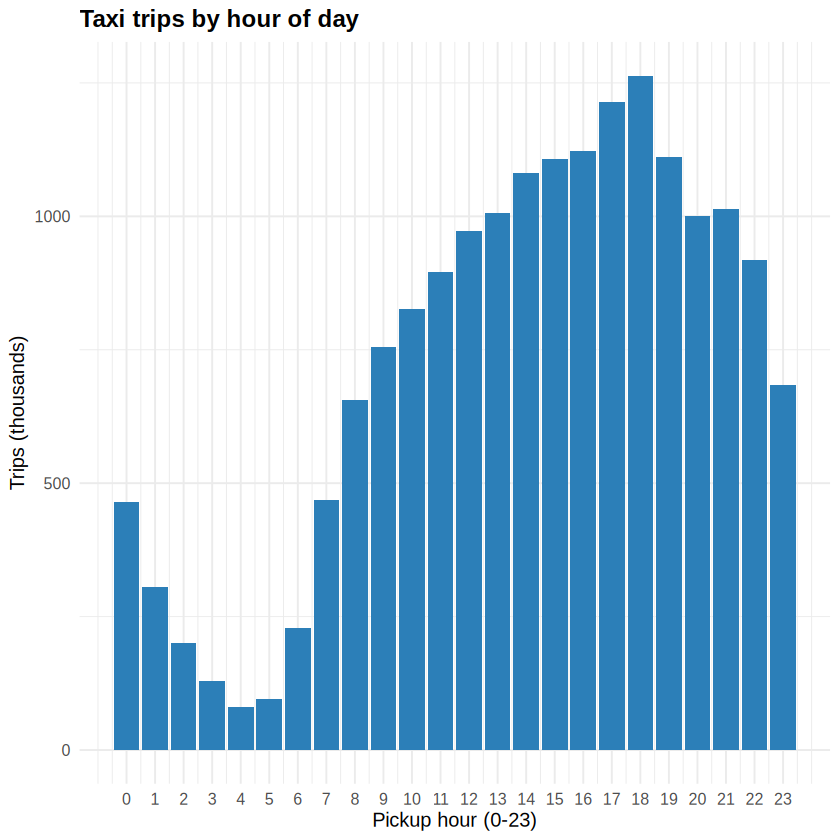

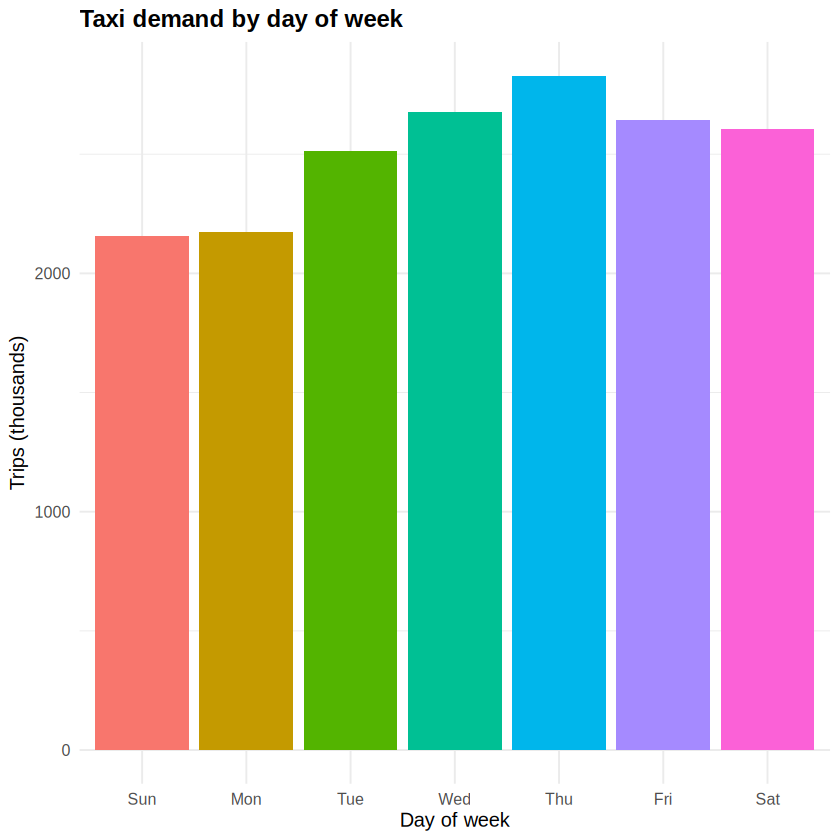

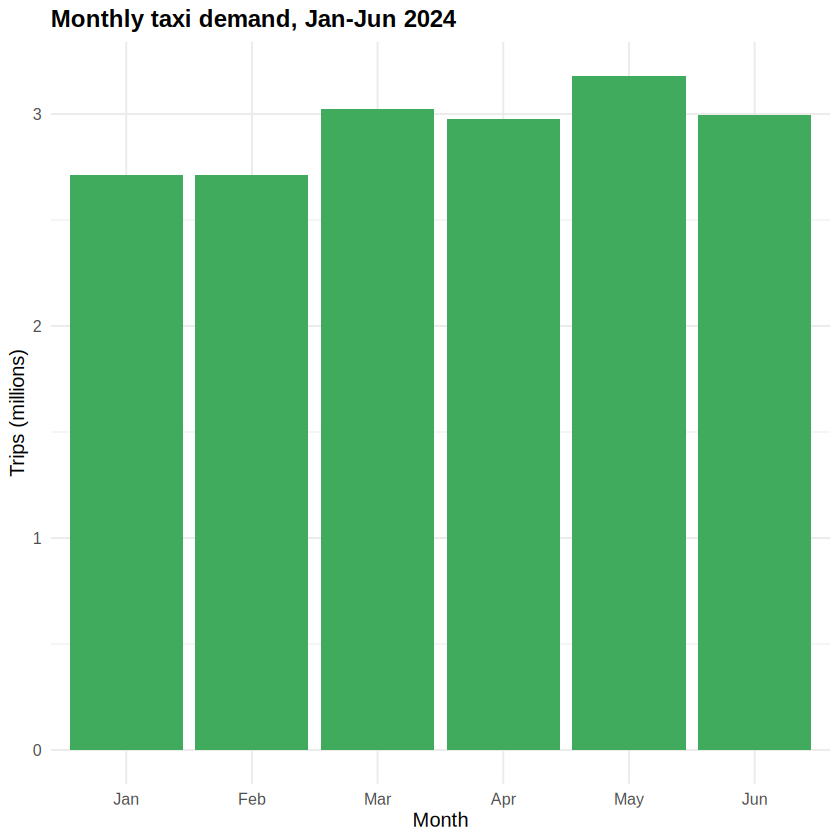

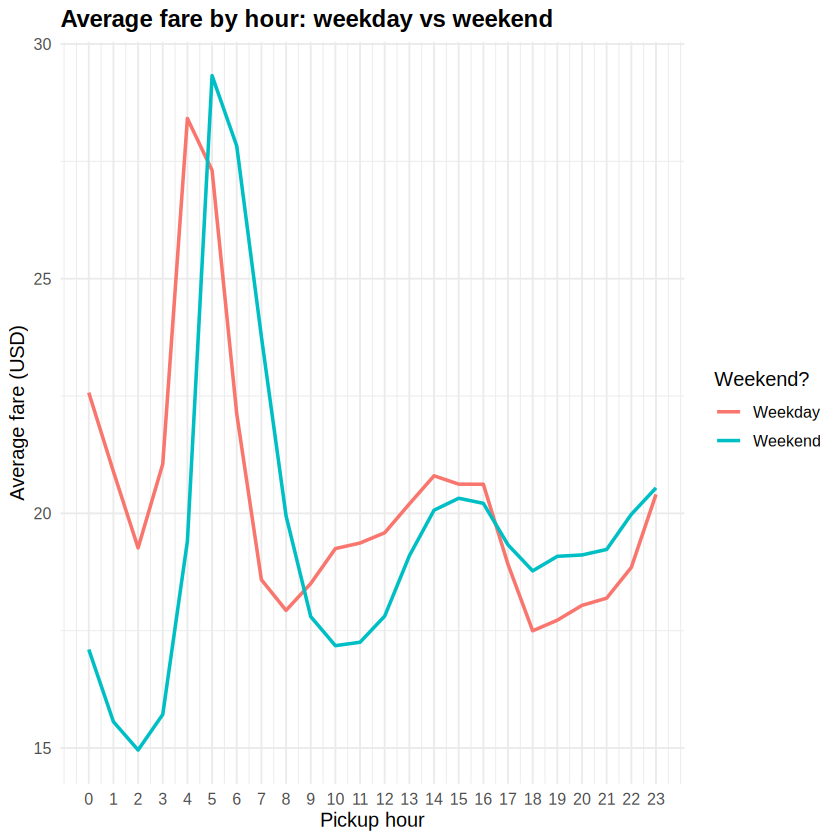

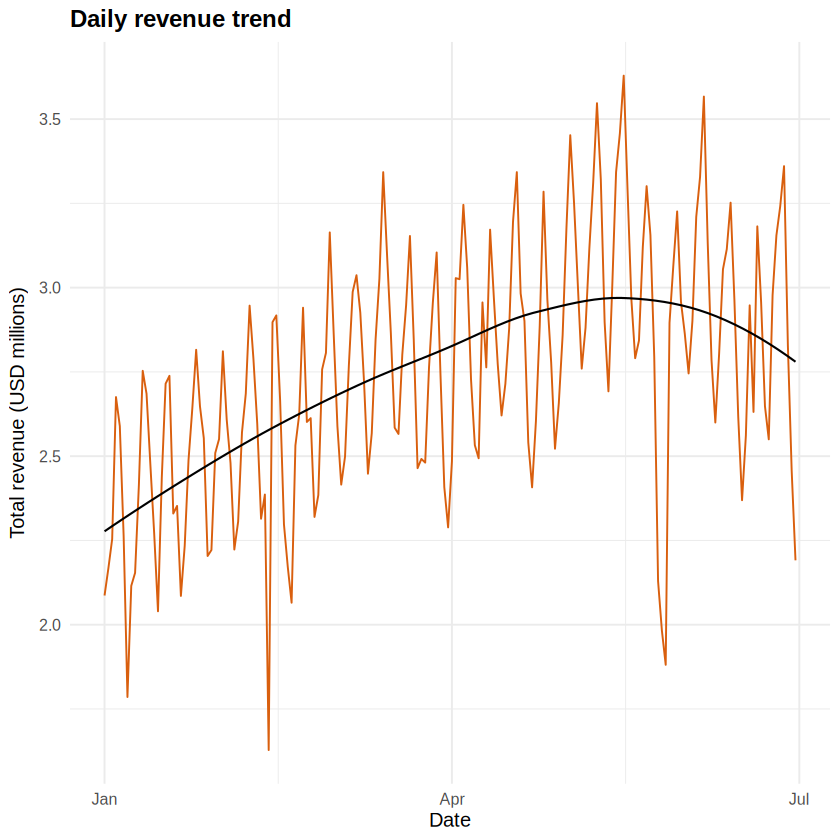

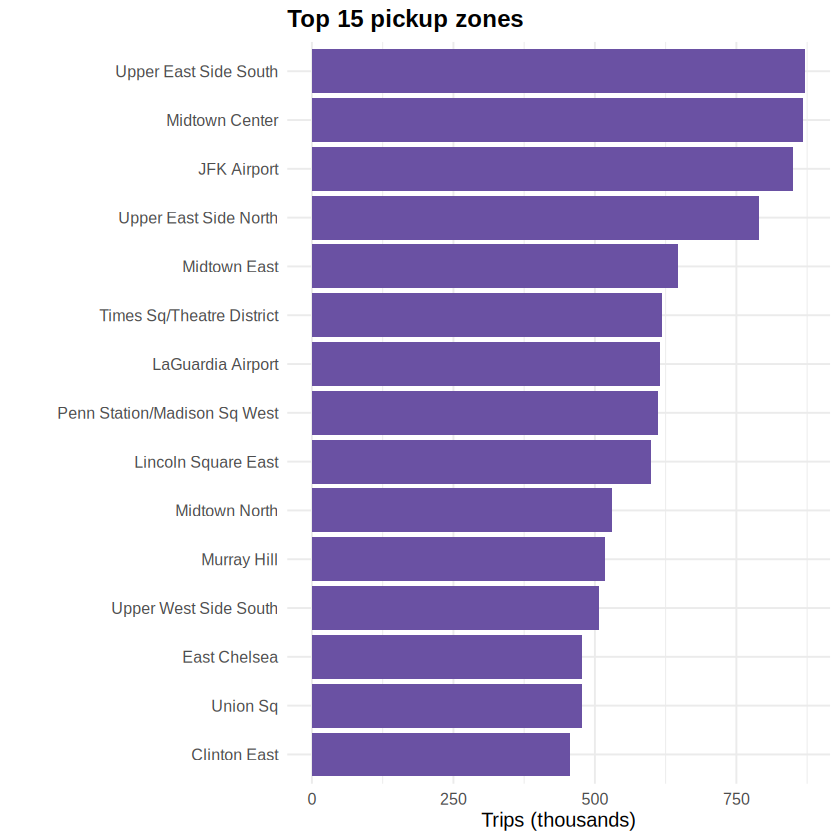

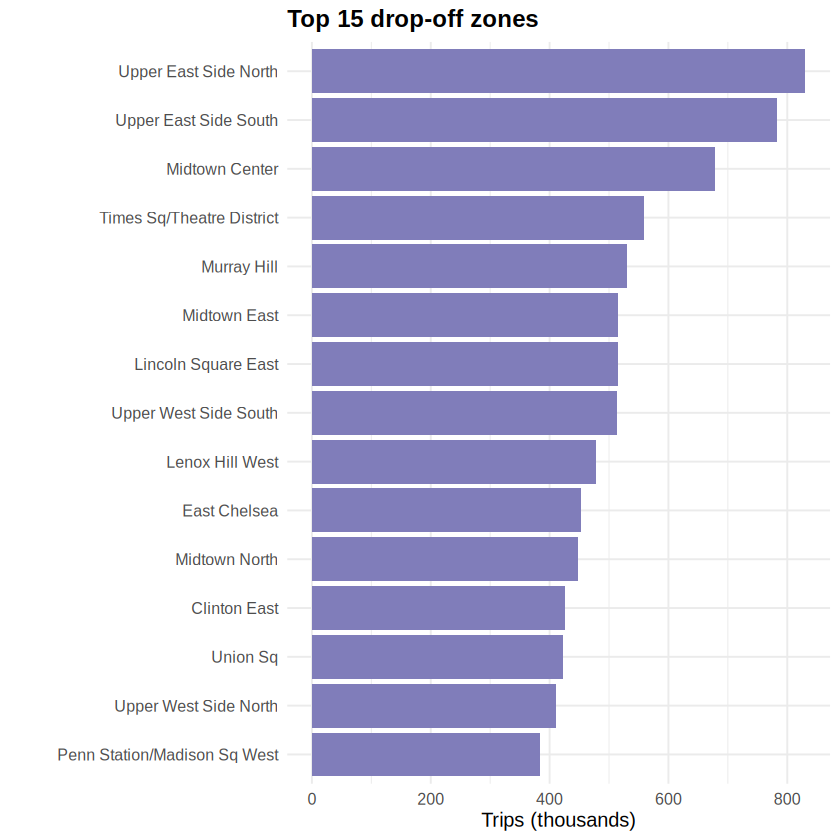

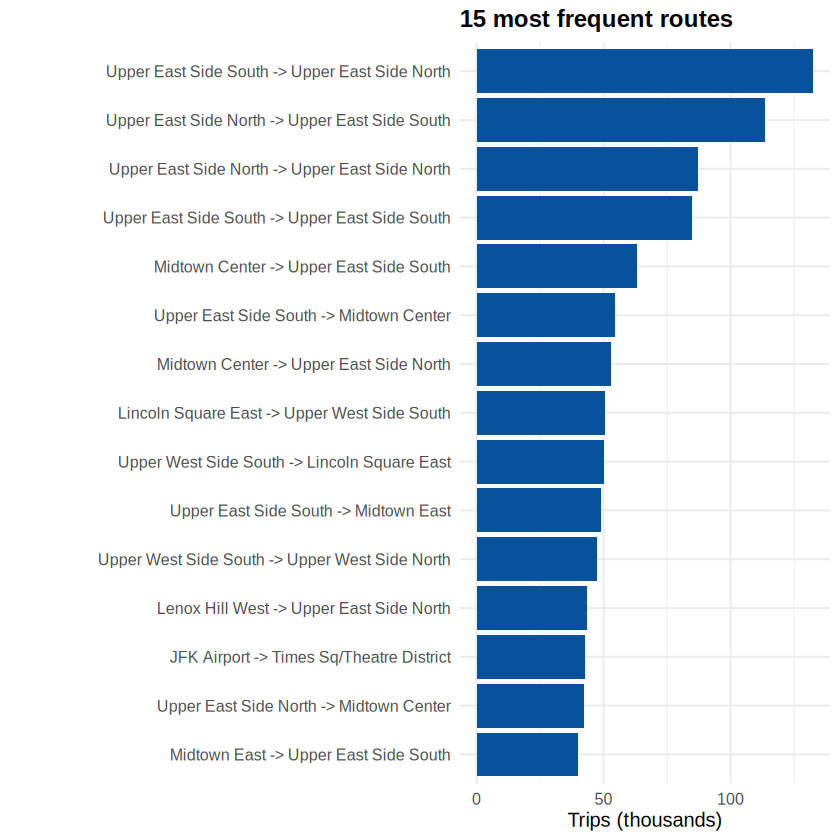

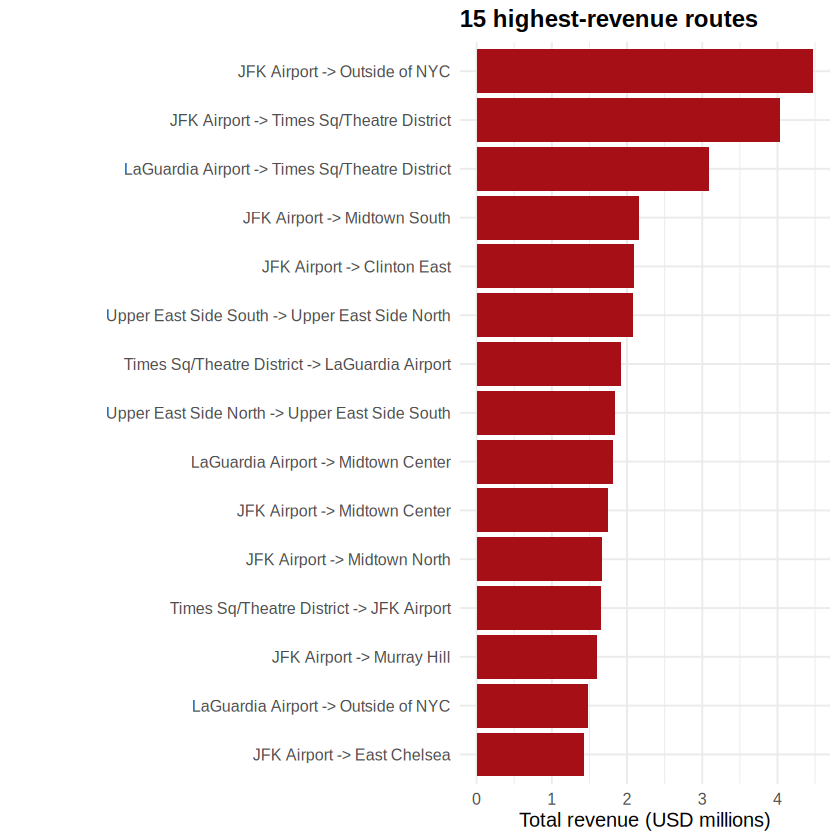

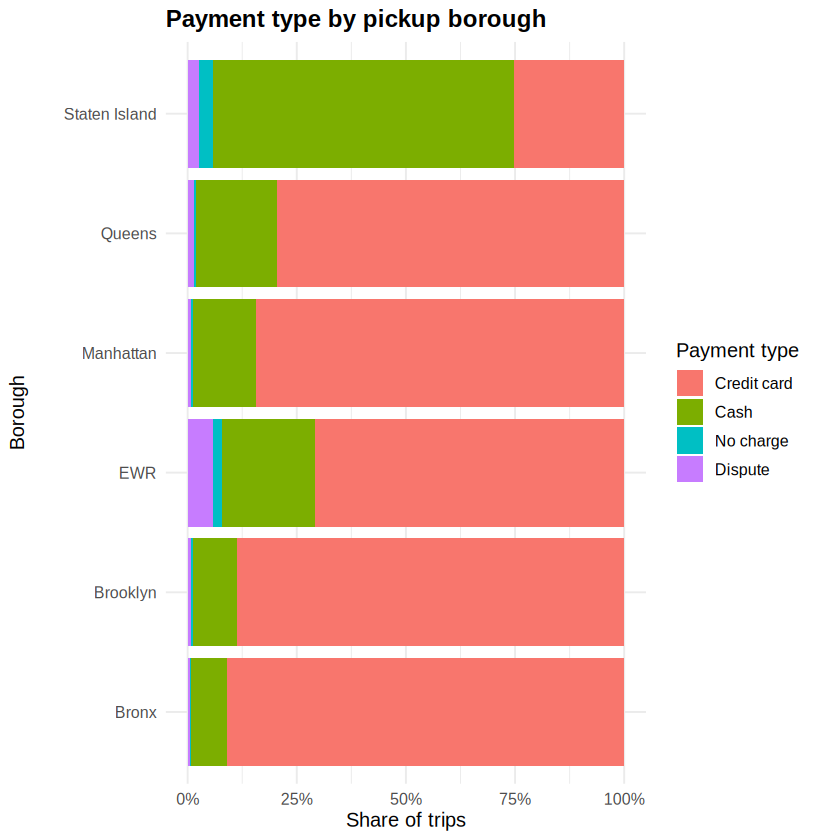

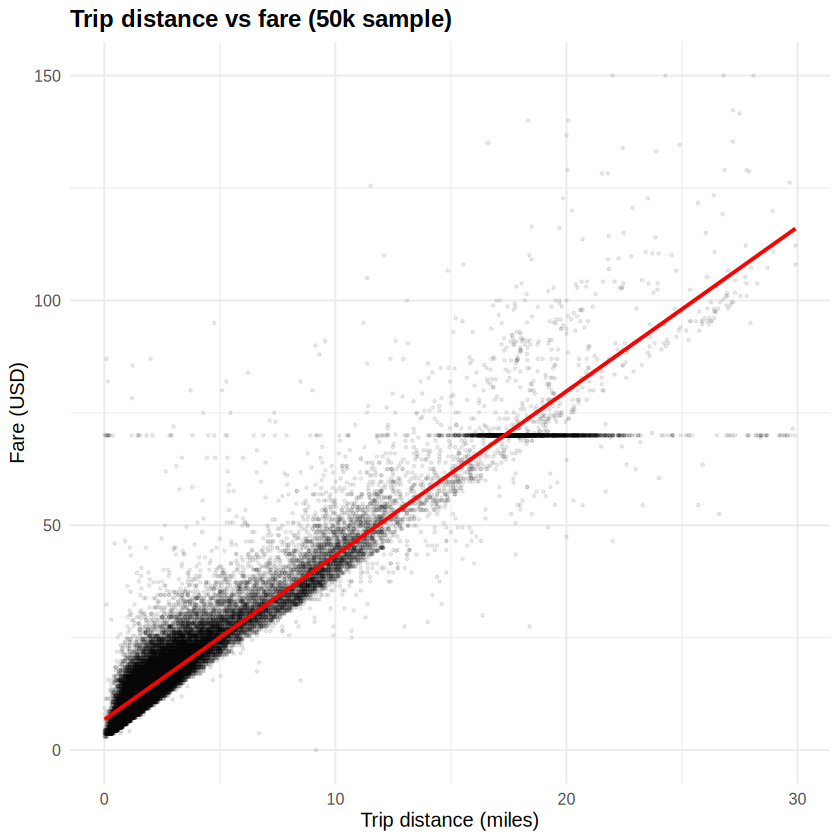

In [20]:
th <- theme_minimal(base_size = 12) + theme(plot.title = element_text(face = "bold"))
sv <- function(p, nm) { print(p); ggsave(file.path("figs", paste0(nm, ".png")), p, width = 9, height = 5, dpi = 150) }

sv(ggplot(by_hour, aes(pickup_hour, trips / 1e3)) + geom_col(fill = "#2c7fb8") +
     scale_x_continuous(breaks = 0:23) +
     labs(title = "Taxi trips by hour of day", x = "Pickup hour (0-23)", y = "Trips (thousands)") + th, "01_trips_by_hour")

sv(ggplot(by_dow, aes(pickup_dow, trips / 1e3, fill = pickup_dow)) + geom_col(show.legend = FALSE) +
     labs(title = "Taxi demand by day of week", x = "Day of week", y = "Trips (thousands)") + th, "02_trips_by_dow")

sv(ggplot(by_month, aes(month_lab, trips / 1e6)) + geom_col(fill = "#41ab5d") +
     labs(title = "Monthly taxi demand, Jan-Jun 2024", x = "Month", y = "Trips (millions)") + th, "03_trips_by_month")

sv(ggplot(by_hour_wk, aes(pickup_hour, avg_fare, colour = is_weekend)) + geom_line(linewidth = 1) +
     scale_colour_discrete(name = "Weekend?", labels = c("Weekday", "Weekend")) +
     scale_x_continuous(breaks = 0:23) +
     labs(title = "Average fare by hour: weekday vs weekend", x = "Pickup hour", y = "Average fare (USD)") + th, "04_avg_fare_hour")

sv(ggplot(daily, aes(pickup_date, revenue / 1e6)) + geom_line(colour = "#d95f0e") +
     geom_smooth(se = FALSE, method = "loess", formula = y ~ x, colour = "black", linewidth = .6) +
     labs(title = "Daily revenue trend", x = "Date", y = "Total revenue (USD millions)") + th, "05_daily_revenue")

sv(ggplot(top_pu, aes(reorder(PU_Zone, N), N / 1e3)) + geom_col(fill = "#6a51a3") + coord_flip() +
     labs(title = "Top 15 pickup zones", x = NULL, y = "Trips (thousands)") + th, "06_top_pickup")
sv(ggplot(top_do, aes(reorder(DO_Zone, N), N / 1e3)) + geom_col(fill = "#807dba") + coord_flip() +
     labs(title = "Top 15 drop-off zones", x = NULL, y = "Trips (thousands)") + th, "07_top_dropoff")

sv(ggplot(top_routes_freq, aes(reorder(route, trips), trips / 1e3)) + geom_col(fill = "#08519c") + coord_flip() +
     labs(title = "15 most frequent routes", x = NULL, y = "Trips (thousands)") + th, "08_top_routes_freq")
sv(ggplot(top_routes_rev, aes(reorder(route, revenue), revenue / 1e6)) + geom_col(fill = "#a50f15") + coord_flip() +
     labs(title = "15 highest-revenue routes", x = NULL, y = "Total revenue (USD millions)") + th, "09_top_routes_rev")

sv(ggplot(pay_borough, aes(PU_Borough, share, fill = payment_type)) + geom_col() +
     scale_y_continuous(labels = percent) + coord_flip() +
     labs(title = "Payment type by pickup borough", x = "Borough", y = "Share of trips", fill = "Payment type") + th, "10_payment")

sv(ggplot(trips[sample(.N, 5e4)][trip_distance <= 30 & fare_amount <= 150],
          aes(trip_distance, fare_amount)) +
     geom_point(alpha = .08, size = .6) + geom_smooth(method = "lm", formula = y ~ x, colour = "red") +
     labs(title = "Trip distance vs fare (50k sample)", x = "Trip distance (miles)", y = "Fare (USD)") + th, "11_dist_vs_fare")

In [23]:
## Optional: leaflet map of pickup zones sized by revenue (needs sf + leaflet)
if (requireNamespace("sf", quietly = TRUE) && requireNamespace("leaflet", quietly = TRUE)) {
  tf <- tempfile(fileext = ".zip")
  download.file("https://d37ci6vzurychx.cloudfront.net/misc/taxi_zones.zip", tf, mode = "wb", quiet = TRUE)
  unzip(tf, exdir = tempdir())
  shp  <- sf::st_read(list.files(tempdir(), "taxi_zones\\.shp$", recursive = TRUE, full.names = TRUE)[1], quiet = TRUE)
  cen  <- sf::st_coordinates(sf::st_transform(suppressWarnings(sf::st_centroid(sf::st_geometry(shp))), 4326))
  geo  <- unique(data.table(LocationID = shp$LocationID, lon = cen[, 1], lat = cen[, 2]), by = "LocationID")
  zrev <- trips[, .(trips = .N, revenue = sum(total_amount)), by = PULocationID]
  geo  <- merge(merge(geo, zrev, by.x = "LocationID", by.y = "PULocationID"), zones, by = "LocationID")
  leaflet::leaflet(geo) |> leaflet::addProviderTiles("CartoDB.Positron") |>
    leaflet::addCircleMarkers(~lon, ~lat, radius = ~sqrt(revenue) / 400, fillOpacity = .5,
      popup = ~sprintf("%s (%s)<br>Trips: %s<br>Revenue: $%s", Zone, Borough,
                       comma(trips), comma(round(revenue))))
}

### Interpretation of Visualizations
_One or two lines per chart: hourly pattern, weekday pattern, monthly pattern, fare trend, revenue trend, top zones, top routes, payment distribution, distance vs fare._

## 10. Critical Analysis (Task 7)
The printed summary below is generated from this run's results. Expand each point in your own words in the next markdown cell.

In [22]:
best  <- bench_all[order(operation, median_ms)][, .SD[1], by = operation]
bp    <- par_heavy[which.max(speedup)]
cat(sprintf("
1. Best performance: %s.
2. data.table: grouping is multi-threaded C code, uses radix ordering, and updates by reference
   (:=, update-joins) so it avoids copying a %.0f MB table.
3. Functional programming (lapply/purrr over groups) is fine for few, heavy, irregular groups or
   when code clarity matters; row-wise apply() is slow (see operation B).
4. Vectorized ops win for element-wise arithmetic: one C-level loop, no per-element R function calls.
5. Parallel: best speedup %.2fx on %d cores (efficiency %.0f%%) for the heavy per-month op.
6. Parallel is NOT always faster: for the cheap op the speedup was %.2fx (cluster start-up and
   data-serialisation overhead dominate). With only %d monthly partitions, speedup is capped
   by load imbalance (Amdahl's law).
7. Trade-offs: speed vs readability (data.table syntax), memory (as.data.frame/split copy data),
   parallel workers duplicate data in RAM.
8. Recommendation: data.table for aggregation/joins; plain vectorized R for column arithmetic;
   lapply/purrr only for per-group complex models; foreach/doParallel only when each task takes
   seconds, not milliseconds.\n",
  best[grepl("A:", operation)]$approach, as.numeric(object.size(trips)) / 2^20,
  bp$speedup, bp$cores, 100 * bp$efficiency, par_cheap[which.max(cores)]$speedup, length(parts)))

cat("\nPeak hour:", by_hour[which.max(trips)]$pickup_hour,
    "| Busiest day:", as.character(by_dow[which.max(trips)]$pickup_dow),
    "| Busiest month:", as.character(by_month[which.max(trips)]$month_lab),
    "| Top route:", top_routes_freq$route[1],
    "| Top revenue route:", top_routes_rev$route[1], "\n")
sessionInfo()


1. Best performance: data.table.
2. data.table: grouping is multi-threaded C code, uses radix ordering, and updates by reference
   (:=, update-joins) so it avoids copying a 2417 MB table.
3. Functional programming (lapply/purrr over groups) is fine for few, heavy, irregular groups or
   when code clarity matters; row-wise apply() is slow (see operation B).
4. Vectorized ops win for element-wise arithmetic: one C-level loop, no per-element R function calls.
5. Parallel: best speedup 1.11x on 2 cores (efficiency 56%) for the heavy per-month op.
6. Parallel is NOT always faster: for the cheap op the speedup was 0.03x (cluster start-up and
   data-serialisation overhead dominate). With only 6 monthly partitions, speedup is capped
   by load imbalance (Amdahl's law).
7. Trade-offs: speed vs readability (data.table syntax), memory (as.data.frame/split copy data),
   parallel workers duplicate data in RAM.
8. Recommendation: data.table for aggregation/joins; plain vectorized R for column ar

R version 4.6.1 (2026-06-24)
Platform: x86_64-pc-linux-gnu
Running under: Ubuntu 24.04.5 LTS

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3 
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.26.so;  LAPACK version 3.12.0

locale:
 [1] LC_CTYPE=en_US.UTF-8       LC_NUMERIC=C              
 [3] LC_TIME=en_US.UTF-8        LC_COLLATE=en_US.UTF-8    
 [5] LC_MONETARY=en_US.UTF-8    LC_MESSAGES=en_US.UTF-8   
 [7] LC_PAPER=en_US.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=en_US.UTF-8 LC_IDENTIFICATION=C       

time zone: Etc/UTC
tzcode source: system (glibc)

attached base packages:
[1] parallel  stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] scales_1.4.0         bench_1.1.4          arrow_25.0.1        
 [4] purrr_1.2.2          microbenchmark_1.5.0 doParallel_1.0.17   
 [7] iterators_1.0.14     for

### Critical Analysis - discussion
_Answer the 8 questions of Task 7 in your own words, supported by the numbers printed above (best performer, role of data.table, when to use functional programming, when vectorization wins, parallel gain, does parallel always help, trade-offs, final recommendation)._

## 11. Conclusion
_Summarize the key analytical findings and the recommended approach for large-scale R analytics, supported by your benchmark results._